In [ ]:
# @title Загрузка библиотек
import pandas as pd
pd.plotting.register_matplotlib_converters()
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
import seaborn as sns
print("Setup Complete")

Setup Complete


In [ ]:
import kagglehub
path = kagglehub.dataset_download("dhairyajeetsingh/ecommerce-customer-behavior-dataset")

Using Colab cache for faster access to the 'ecommerce-customer-behavior-dataset' dataset.


In [ ]:
# @title Загрузка и просмотр данных
import os
#print("файлов в папке: ", len(os.listdir(path)))
csvpath = os.path.join(path, os.listdir(path)[0])
df = pd.read_csv(csvpath)
df.head(5)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# @title Базовая проверка на требования к dataset
print("Размер датасета (строки, столбцы):", df.shape, "\n")

print("Типы данных по столбцам: \n", df.dtypes, "\n")

print("Пропуски по столбцам: \n", df.isnull().sum(), "\n" ) #isnull() - проверяет отсутствие и присутствие значения (True и False соответственно)

print("Статистическое описание числовых признаков: \n",) # тут анализируем где у нас могут быть некорректные значения
# смотрим на min и max: там видны значения, которых не может быть в реальности
df.describe()

Размер датасета (строки, столбцы): (50000, 25) 

Типы данных по столбцам: 
 Age                              float64
Gender                            object
Country                           object
City                              object
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance        

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,...,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,...,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,...,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,...,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,...,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,...,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,...,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


In [ ]:
# @title Предпросмотр категориальных данных, для дальнейшей обработки
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} уникальных значений")
    print(df[col].unique())

Gender: 3 уникальных значений
['Male' 'Female' 'Other']
Country: 8 уникальных значений
['France' 'UK' 'Canada' 'USA' 'India' 'Japan' 'Germany' 'Australia']
City: 40 уникальных значений
['Marseille' 'Manchester' 'Vancouver' 'New York' 'Delhi' 'Tokyo' 'Berlin'
 'Houston' 'Calgary' 'Glasgow' 'Munich' 'Phoenix' 'Paris' 'Ottawa'
 'Los Angeles' 'Bangalore' 'Adelaide' 'Yokohama' 'Sydney' 'Nagoya'
 'Frankfurt' 'Cologne' 'Hamburg' 'Nice' 'Chicago' 'Toulouse' 'Brisbane'
 'Leeds' 'Mumbai' 'Montreal' 'Melbourne' 'Osaka' 'Lyon' 'Hyderabad'
 'Chennai' 'Birmingham' 'London' 'Toronto' 'Perth' 'Kyoto']
Signup_Quarter: 4 уникальных значений
['Q1' 'Q4' 'Q2' 'Q3']


In [ ]:
# @title Кодирование признаков, представленных в виде строк

for col in cat_cols:
    df[col] = pd.factorize(df[col])[0]

df.head(10)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,0,0,0,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,0
1,36.0,0,1,1,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,1
2,45.0,1,2,2,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,1
3,56.0,1,3,3,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,0
4,35.0,0,4,4,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,1
5,35.0,0,5,5,3.5,6.0,21.9,6.9,74.4,0.0,...,16.0,8.0,2.0,14.3,11.2,2.0,1995.43,2418.0,1,0
6,56.0,0,6,6,1.9,24.0,46.4,13.9,36.2,5.0,...,35.5,4.0,6.0,68.8,42.9,5.0,3003.57,2657.0,0,0
7,47.0,1,3,7,1.6,14.0,24.1,8.3,59.9,2.0,...,5.5,5.0,NaN,30.1,7.6,2.0,1394.04,2274.0,0,1
8,32.0,0,2,8,1.3,14.0,NaN,7.4,66.5,4.0,...,19.0,2.0,0.0,0.0,18.7,2.0,537.21,534.0,0,0
9,44.0,0,3,3,3.6,13.0,31.3,5.4,62.6,3.0,...,11.7,2.0,1.0,13.5,21.5,2.0,807.84,977.0,0,2


In [ ]:
# @title Заполнение пропусков медианой
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    missing_before = df[col].isnull().sum()
    if missing_before > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"{col}: заполнено {missing_before} пропусков медианой = {round(median_val,2)}")

print()
print("Осталось пропусков всего:", df.isnull().sum().sum())

Age: заполнено 2495 пропусков медианой = 38.0
Session_Duration_Avg: заполнено 3399 пропусков медианой = 26.8
Pages_Per_Session: заполнено 3000 пропусков медианой = 8.4
Wishlist_Items: заполнено 4000 пропусков медианой = 4.0
Days_Since_Last_Purchase: заполнено 3000 пропусков медианой = 21.0
Discount_Usage_Rate: заполнено 3500 пропусков медианой = 40.2
Returns_Rate: заполнено 4491 пропусков медианой = 5.4
Email_Open_Rate: заполнено 2528 пропусков медианой = 19.7
Customer_Service_Calls: заполнено 168 пропусков медианой = 5.0
Product_Reviews_Written: заполнено 3500 пропусков медианой = 2.0
Social_Media_Engagement_Score: заполнено 6000 пропусков медианой = 27.6
Mobile_App_Usage: заполнено 5000 пропусков медианой = 18.6
Payment_Method_Diversity: заполнено 2500 пропусков медианой = 2.0
Credit_Balance: заполнено 5500 пропусков медианой = 1896.0

Осталось пропусков всего: 0


In [ ]:
# @title Нормализация
from sklearn.preprocessing import RobustScaler
num_cols = [col for col in df.columns if col not in cat_cols and col != 'Churned']

scaler = RobustScaler()
df_normalized = df.copy()
df_normalized[num_cols] = scaler.fit_transform(df[num_cols])

print()
print("Данные после нормализации:")
df_normalized[num_cols].describe()


Данные после нормализации:


,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04,50000.000000
mean,-0.012480,0.186157,0.056787,0.058133,0.066155,-0.045741,0.068630,0.123508,0.176814,0.275510,0.057524,0.211975,0.061218,0.226513,0.264527,0.061131,0.060916,0.33618,1.818986e-01,0.041672
std,0.769046,0.791963,0.710060,0.760669,0.763333,0.730167,0.765143,0.779701,3.059239,0.962201,0.709466,1.067651,0.723449,0.890615,0.752161,0.760182,0.784112,1.08465,8.368051e-01,0.770625
min,-2.200000,-0.923077,-1.000000,-1.869565,-1.541667,-2.605381,-1.000000,-2.777778,-1.508799,-0.700000,-1.375086,-0.981818,-1.026042,-1.666667,-0.666667,-1.086614,-1.631579,-1.00000,-1.146869e+00,-1.264000
25%,-0.533333,-0.423077,-0.454545,-0.478261,-0.458333,-0.524664,-0.500000,-0.444444,-0.451647,-0.400000,-0.471438,-0.418182,-0.479167,-0.333333,-0.333333,-0.484252,-0.473684,0.00000,-4.183774e-01,-0.488000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1.048593e-16,0.000000
75%,0.466667,0.576923,0.545455,0.521739,0.541667,0.475336,0.500000,0.555556,0.548353,0.600000,0.528562,0.581818,0.520833,0.666667,0.666667,0.515748,0.526316,1.00000,5.816226e-01,0.512000
max,10.800000,2.884615,3.181818,3.536232,3.270833,3.840509,6.000000,12.966667,166.464701,8.866667,2.630420,17.130133,3.750000,5.333333,6.333333,2.850394,3.798246,3.00000,7.142547e+00,3.534000


In [ ]:
# @title Ищем дубликаты
print("Найдено дубликатов:", df.duplicated().sum())  # дубликатов у нас нет, поэтому ничего не удаляем

Найдено дубликатов: 0


In [ ]:
df.head(5)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,0,0,0,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,0
1,36.0,0,1,1,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,27.6,23.3,3.0,1067.47,3028.0,0,1
2,45.0,1,2,2,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,27.6,8.8,2.0,1289.75,2317.0,0,1
3,56.0,1,3,3,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,0
4,35.0,0,4,4,3.1,29.0,51.4,8.4,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,1


In [ ]:
df_normalized.head(5)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,0.333333,0,0,0,0.153846,0.272727,0.043478,-0.500000,-0.336323,-0.25,...,-0.093750,1.333333,0.666667,-0.444882,0.192982,-1.0,-0.267561,0.254667,0,0
1,-0.133333,0,1,1,-0.346154,0.363636,1.152174,0.395833,-0.914798,-0.75,...,1.203125,0.666667,0.333333,0.000000,0.412281,1.0,-0.162284,0.754667,0,1
2,0.466667,1,2,2,0.153846,-0.090909,-0.144928,-1.416667,0.573991,-0.75,...,-1.026042,-0.333333,-0.333333,0.000000,-0.859649,0.0,0.042737,0.280667,0,1
3,1.200000,1,3,3,0.038462,-0.090909,0.840580,1.333333,-0.735426,1.25,...,1.130208,-1.000000,1.000000,2.295276,1.087719,1.0,1.012288,0.518667,0,0
4,-0.200000,0,4,4,0.230769,1.636364,1.782609,0.000000,-1.748879,1.25,...,0.947917,-1.333333,3.000000,2.181102,2.789474,2.0,1.658277,2.305333,0,1


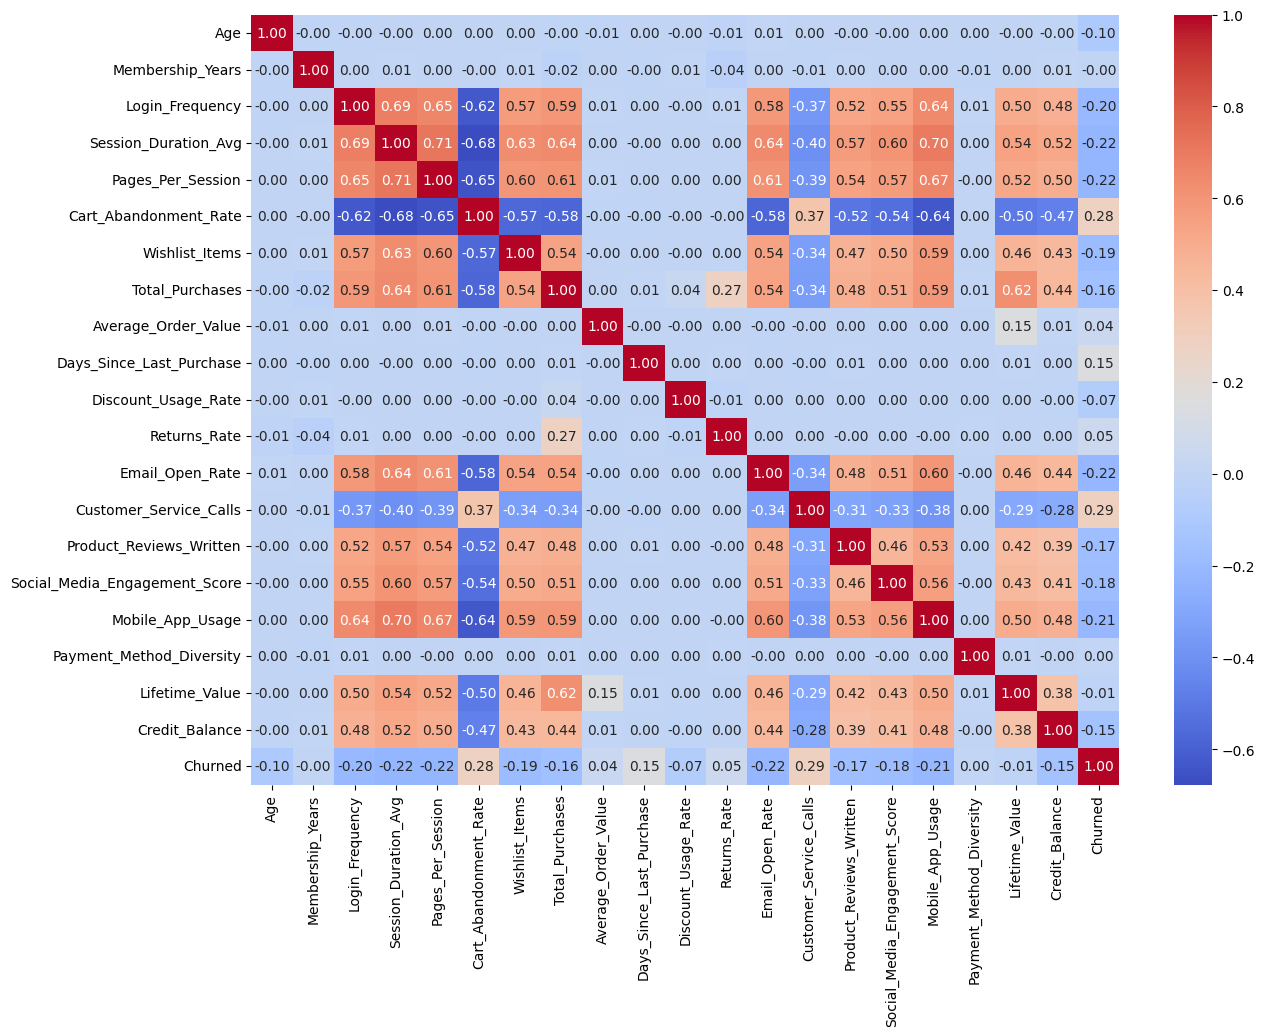

In [ ]:
#@title Корреляции
plt.figure(figsize=(14, 10))
# df.drop(columns=cat_cols).corr() - убрали категориальные столбцы
sns.heatmap(df.drop(columns=cat_cols).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

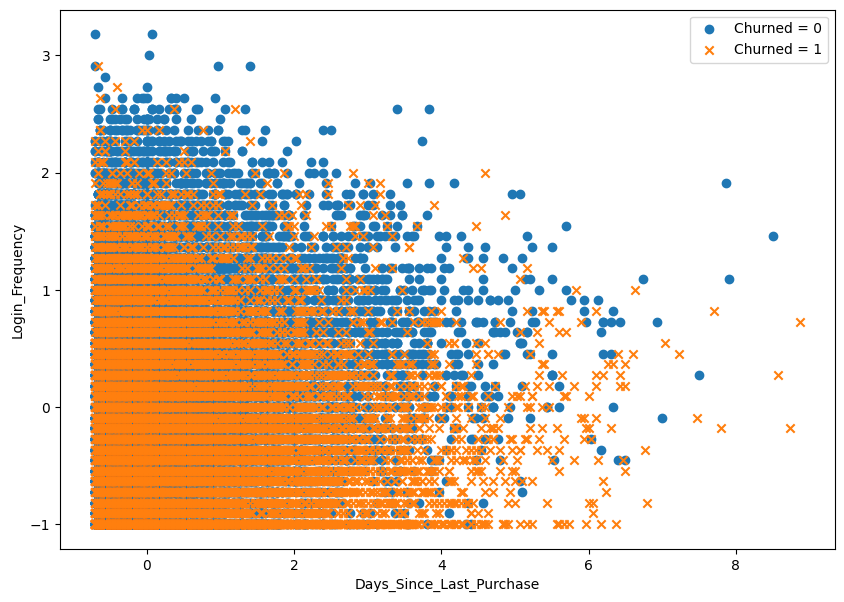

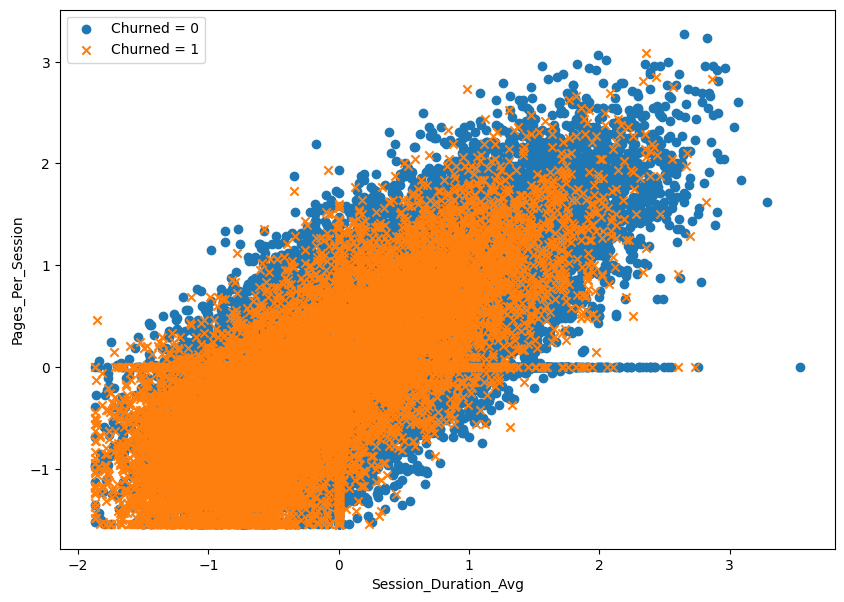

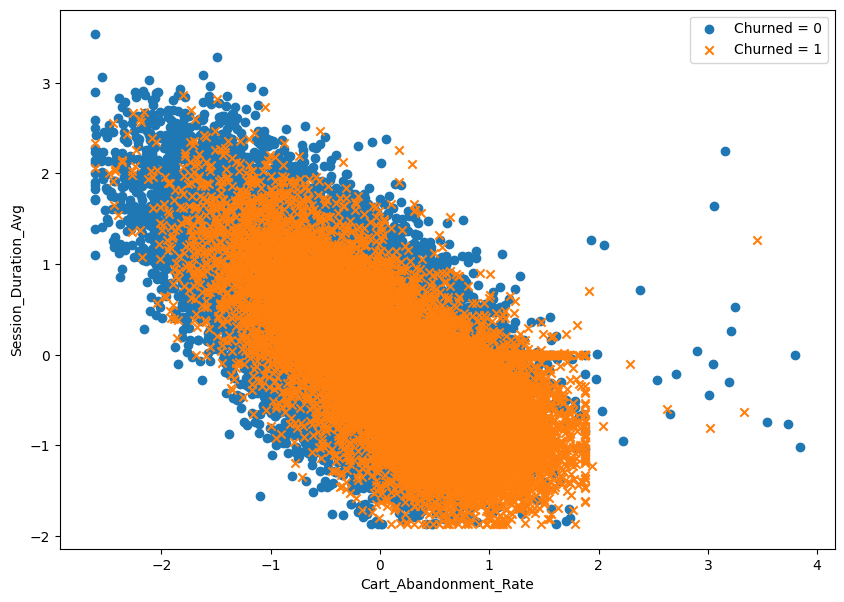

In [ ]:
# @title Диаграммы рассеяния
# 1. Days_Since_Last_Purchase vs Login_Frequency
plt.figure(figsize=(10, 7))

plt.scatter(
    'Days_Since_Last_Purchase',
    'Login_Frequency',
    data=df_normalized[df_normalized.Churned == 0],
    marker='o'
)

plt.scatter(
    'Days_Since_Last_Purchase',
    'Login_Frequency',
    data=df_normalized[df_normalized.Churned == 1],
    marker='x'
)

plt.xlabel('Days_Since_Last_Purchase')
plt.ylabel('Login_Frequency')
plt.legend(('Churned = 0', 'Churned = 1'))
plt.show()


# 2. Session_Duration_Avg и Pages_Per_Session
plt.figure(figsize=(10, 7))

plt.scatter(
    'Session_Duration_Avg',
    'Pages_Per_Session',
    data=df_normalized[df_normalized.Churned == 0],
    marker='o'
)

plt.scatter(
    'Session_Duration_Avg',
    'Pages_Per_Session',
    data=df_normalized[df_normalized.Churned == 1],
    marker='x'
)

plt.xlabel('Session_Duration_Avg')
plt.ylabel('Pages_Per_Session')
plt.legend(('Churned = 0', 'Churned = 1'))
plt.show()


# 3. Cart_Abandonment_Rate и Session_Duration_Avg
plt.figure(figsize=(10, 7))

plt.scatter(
    'Cart_Abandonment_Rate',
    'Session_Duration_Avg',
    data=df_normalized[df_normalized.Churned == 0],
    marker='o'
)

plt.scatter(
    'Cart_Abandonment_Rate',
    'Session_Duration_Avg',
    data=df_normalized[df_normalized.Churned == 1],
    marker='x'
)

plt.xlabel('Cart_Abandonment_Rate')
plt.ylabel('Session_Duration_Avg')
plt.legend(('Churned = 0', 'Churned = 1'))
plt.show()

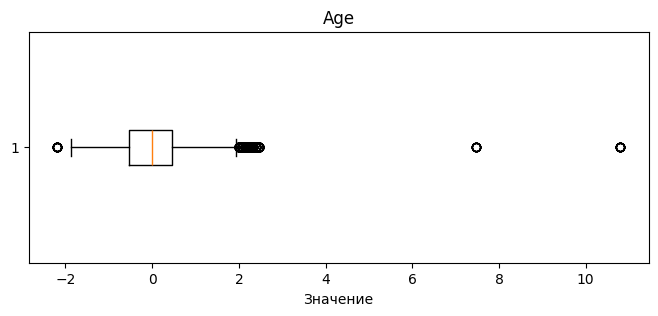

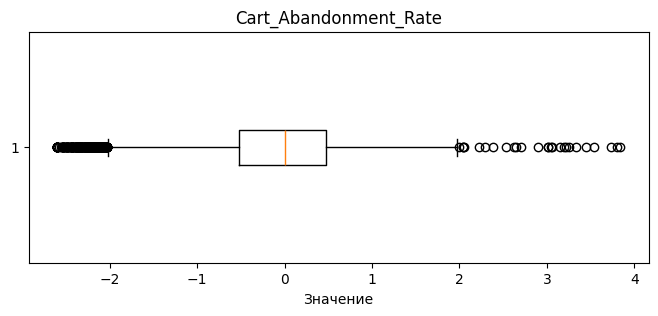

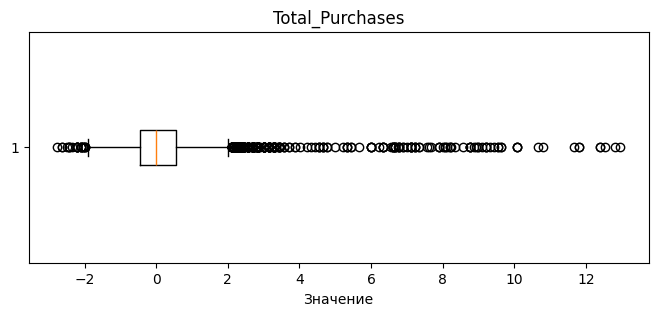

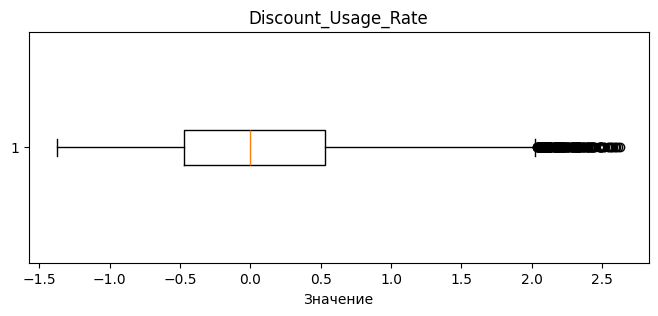

In [ ]:
# @title Ящики с усами
# 1. Age
plt.figure(figsize=(8, 3))
plt.boxplot(df_normalized['Age'], vert=False)
plt.xlabel('Значение')
plt.title('Age')
plt.show()

# 2. Cart_Abandonment_Rate
plt.figure(figsize=(8, 3))
plt.boxplot(df_normalized['Cart_Abandonment_Rate'], vert=False)
plt.xlabel('Значение')
plt.title('Cart_Abandonment_Rate')
plt.show()

# 3. Total_Purchases
plt.figure(figsize=(8, 3))
plt.boxplot(df_normalized['Total_Purchases'], vert=False)
plt.xlabel('Значение')
plt.title('Total_Purchases')
plt.show()

# 4. Discount_Usage_Rate
plt.figure(figsize=(8, 3))
plt.boxplot(df_normalized['Discount_Usage_Rate'], vert=False)
plt.xlabel('Значение')
plt.title('Discount_Usage_Rate')
plt.show()


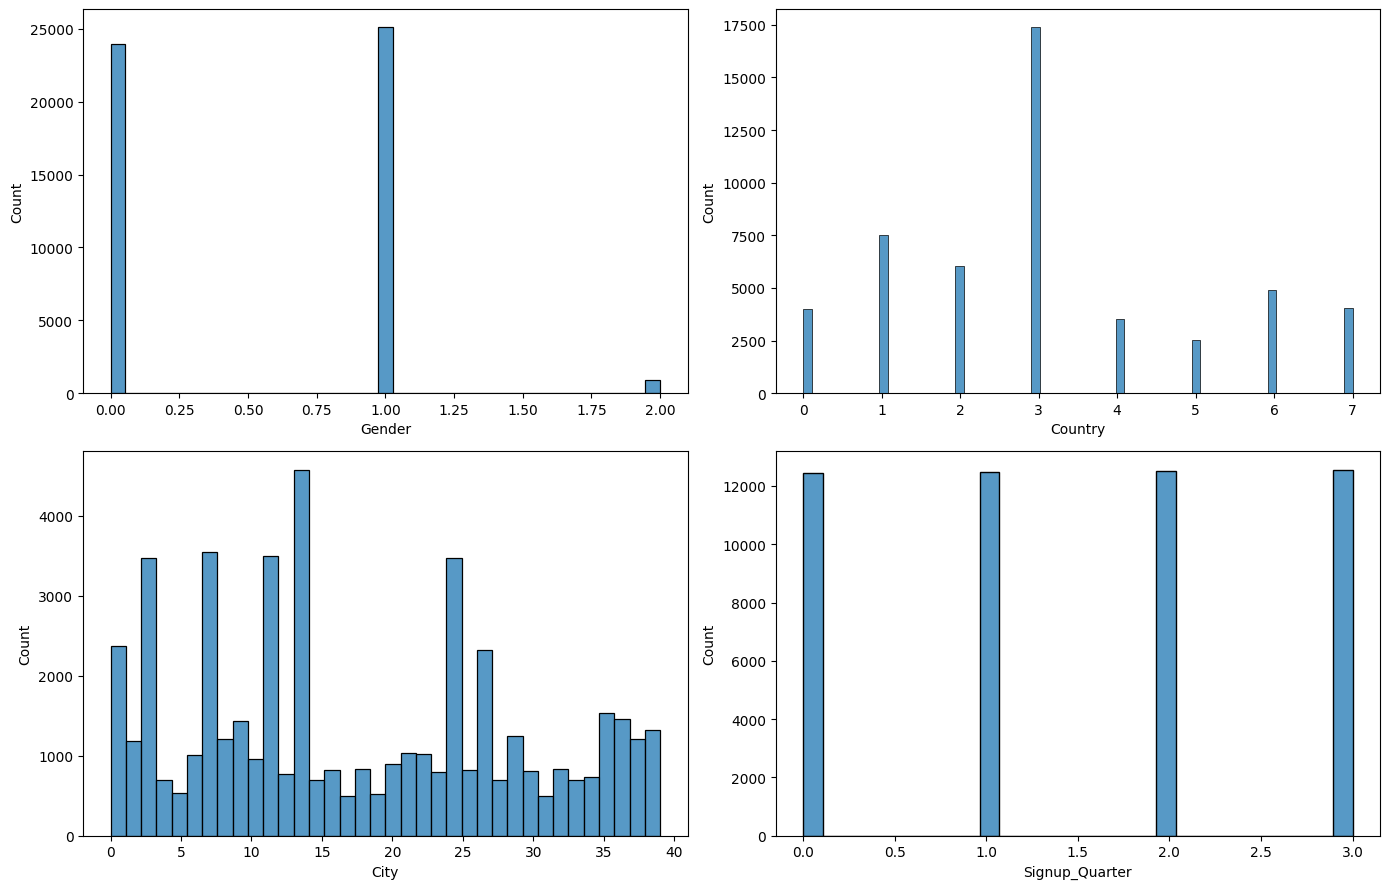

In [ ]:
# @title Гистограммы (по категориальным)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df_normalized['Gender'], ax=axes[0,0])

sns.histplot(df_normalized['Country'], ax=axes[0,1])

sns.histplot(df_normalized['City'], ax=axes[1,0])

sns.histplot(df_normalized['Signup_Quarter'], ax=axes[1,1])

plt.tight_layout()
plt.show()

<Axes: xlabel='Email_Open_Rate', ylabel='Count'>

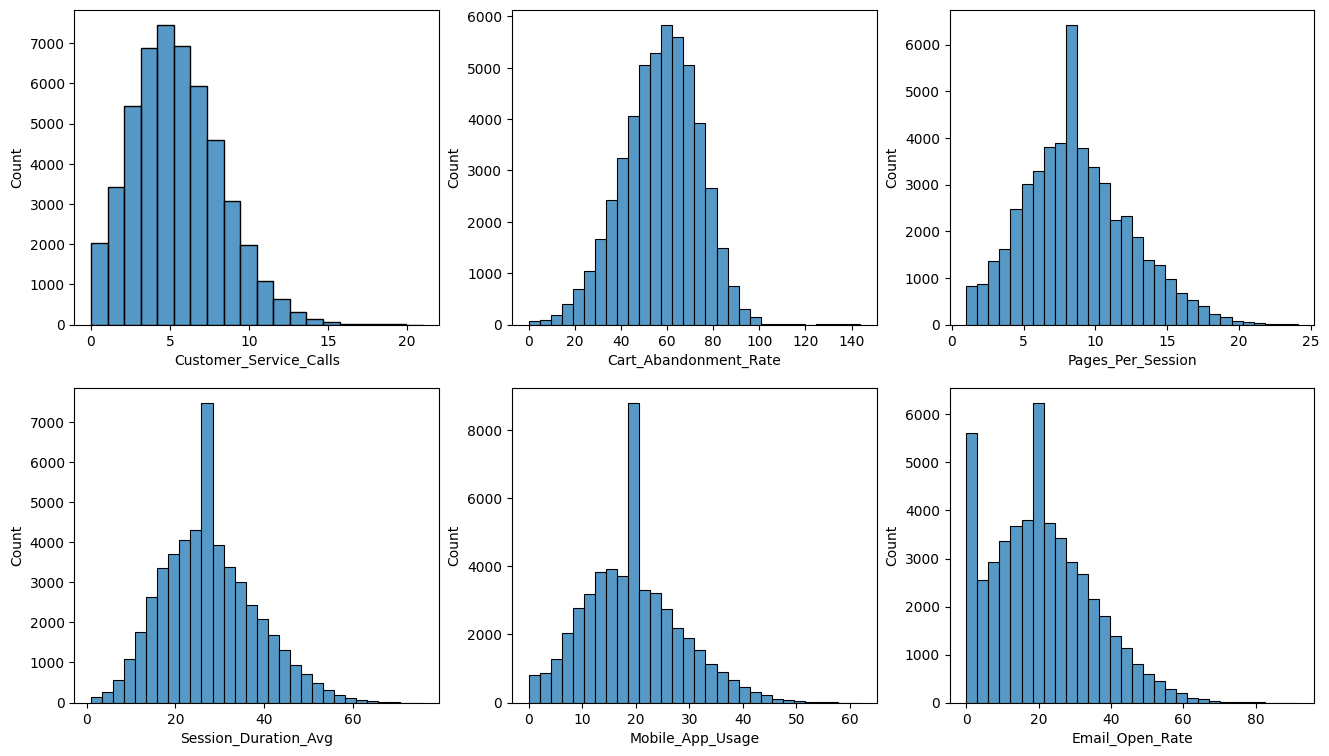

In [ ]:
# @title Гистрограммы (не по категориальным)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(df['Customer_Service_Calls'], bins=20, ax=axes[0,0])

sns.histplot(df['Cart_Abandonment_Rate'], bins=30, ax=axes[0,1])

sns.histplot(df['Pages_Per_Session'], bins=30, ax=axes[0,2])

sns.histplot(df['Session_Duration_Avg'], bins=30, ax=axes[1,0])

sns.histplot(df['Mobile_App_Usage'], bins=30, ax=axes[1,1])

sns.histplot(df['Email_Open_Rate'], bins=30, ax=axes[1,2])

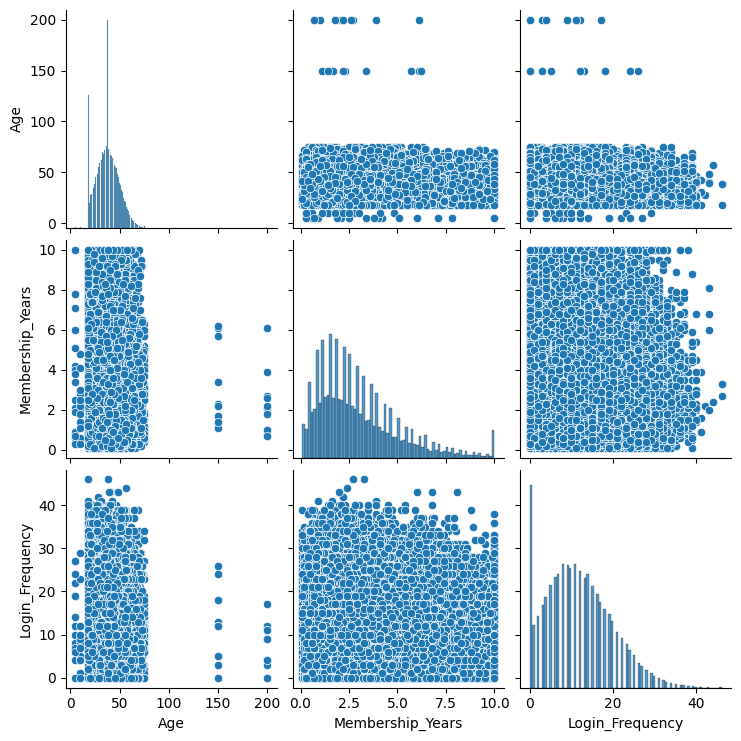

In [ ]:
# @title Первичная матрица пример for as
numeric = ['Age', 'Membership_Years', 'Login_Frequency']
sns.pairplot(df[numeric]);

In [ ]:
# @title Первичная матрица all
#num_cols = [x for x in df.select_dtypes(include=['number']).columns if x not in cat_cols]
#sns.pairplot(df[num_cols])
#plt.show()

In [ ]:
# @title Функции for выбросов
def outliers_indices(feature):
    mid = df[feature].mean()
    sigma = df[feature].std()

    return df[
        (df[feature] < mid - 3 * sigma) |
        (df[feature] > mid + 3 * sigma)
    ].index

In [ ]:
# @title Реализация delete выбросов
out = set()

for feature in num_cols:
    out.update(outliers_indices(feature))

print('Количество выбросов:', len(out))

df.drop(out, inplace=True)

Количество выбросов: 4745


In [ ]:
# @title Удаление логически невозможных значений
invalid = df[
    (df['Total_Purchases'] < 0) |
    (df['Cart_Abandonment_Rate'] > 100) |
    (df['Discount_Usage_Rate'] > 100)
].index

print('Логически некорректных строк:', len(invalid))
df.drop(invalid, inplace=True)

Логически некорректных строк: 113


In [ ]:
# @title Матрицы without выбросов
#sns.pairplot(df[num_cols])
#plt.show()

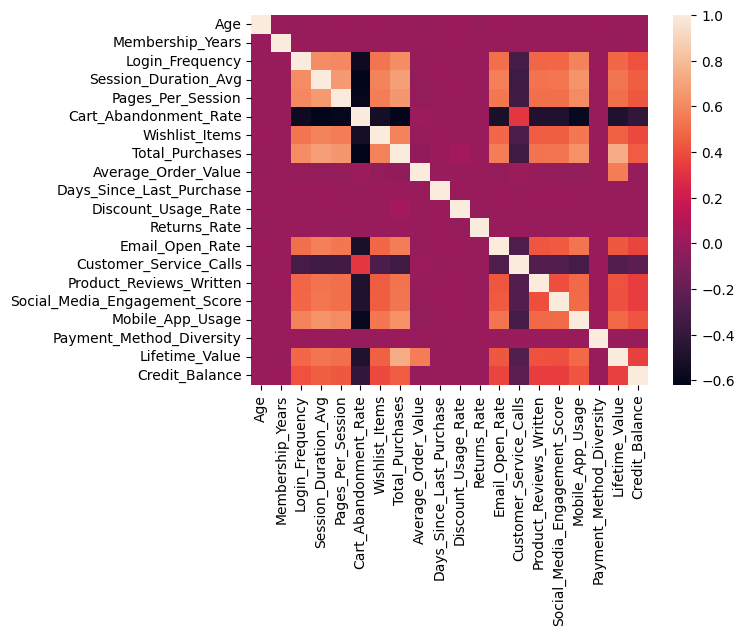

In [ ]:
# @title тепловая map
sns.heatmap(
    df[num_cols].corr(method='spearman')
)
plt.show()

In [ ]:
# @title Подготовка к статистическому анализ
from scipy import stats
alpha = 0.05
feat_cols = [x for x in num_cols if x != 'Churned']

print('Числовых признаков для анализа:', len(feat_cols))
print(feat_cols)
print('Категориальные признаки (для хи-квадрата):', list(cat_cols))
print('Целевая переменная: Churned')

Числовых признаков для анализа: 20
['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance']
Категориальные признаки (для хи-квадрата): ['Gender', 'Country', 'City', 'Signup_Quarter']
Целевая переменная: Churned


In [ ]:
# @title Инструмент 1. describe — форма распределения признаков
rows = []

for col in feat_cols:
    d = stats.describe(df[col].values)
    rows.append({
        'Признак': col,
        'N': d.nobs,
        'Минимум': round(d.minmax[0], 3),
        'Максимум': round(d.minmax[1], 3),
        'Среднее': round(d.mean, 3),
        'Медиана': round(df[col].median(), 3),
        'Дисперсия': round(d.variance, 3),
        'Асимметрия': round(d.skewness, 3),
        'Эксцесс': round(d.kurtosis, 3),
    })

describe_table = pd.DataFrame(rows).set_index('Признак')

skewed = describe_table[describe_table['Асимметрия'].abs() > 0.5]
print('Признаков с заметной асимметрией (|skew| > 0.5):', len(skewed))
print(list(skewed.index) if len(skewed) else 'таких нет')
print('Чем сильнее асимметрия, тем больше расходятся среднее и медиана —')
print('сравните два соответствующих столбца в таблице ниже.')
describe_table


Признаков с заметной асимметрией (|skew| > 0.5): 9
['Membership_Years', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Returns_Rate', 'Product_Reviews_Written', 'Payment_Method_Diversity', 'Lifetime_Value']
Чем сильнее асимметрия, тем больше расходятся среднее и медиана —
сравните два соответствующих столбца в таблице ниже.


,N,Минимум,Максимум,Среднее,Медиана,Дисперсия,Асимметрия,Эксцесс
Признак,,,,,,,,
Age,45142,5.00,72.00,37.699,38.000,122.867,0.190,-0.340
Membership_Years,45142,0.10,9.10,2.876,2.500,3.516,0.903,0.361
Login_Frequency,45142,0.00,35.00,11.046,11.000,53.523,0.419,-0.371
Session_Duration_Avg,45142,1.00,59.00,26.749,26.800,94.224,0.274,-0.096
Pages_Per_Session,45142,1.00,19.70,8.451,8.400,11.734,0.285,-0.133
Cart_Abandonment_Rate,45142,8.30,100.00,58.191,58.900,233.499,-0.189,-0.230
Wishlist_Items,45142,0.00,13.00,4.032,4.000,7.634,0.742,0.241
Total_Purchases,45142,0.00,34.00,12.448,12.000,32.801,0.578,0.138
Average_Order_Value,45142,26.87,378.46,118.271,112.270,1852.604,0.829,0.974


In [ ]:
# @title Инструмент 2. Дисперсия и коэффициент вариации — анализ вариативности признаков

rows = []

for col in feat_cols:
    mean = df[col].mean()
    variance = df[col].var()
    std = df[col].std()

    cv = (std / mean) * 100 if mean != 0 else np.nan

    if pd.isna(cv):
        interpretation = 'не рассчитывается'
    elif cv < 10:
        interpretation = 'низкая вариативность'
    elif cv < 20:
        interpretation = 'умеренная вариативность'
    elif cv < 33:
        interpretation = 'значительная вариативность'
    else:
        interpretation = 'высокая вариативность'

    rows.append({
        'Признак': col,
        'Среднее': round(mean, 3),
        'Дисперсия': round(variance, 3),
        'Стандартное отклонение': round(std, 3),
        'Коэффициент вариации, %': round(cv, 2),
        'Интерпретация': interpretation
    })

variation_table = (
    pd.DataFrame(rows)
    .set_index('Признак')
    .sort_values('Коэффициент вариации, %', ascending=False)
)

variation_table

,Среднее,Дисперсия,Стандартное отклонение,"Коэффициент вариации, %",Интерпретация
Признак,,,,,
Days_Since_Last_Purchase,26.909,555.538,23.570,87.59,высокая вариативность
Product_Reviews_Written,2.617,4.095,2.024,77.33,высокая вариативность
Returns_Rate,6.341,19.660,4.434,69.92,высокая вариативность
Wishlist_Items,4.032,7.634,2.763,68.52,высокая вариативность
Login_Frequency,11.046,53.523,7.316,66.23,высокая вариативность
Email_Open_Rate,19.878,169.740,13.028,65.54,высокая вариативность
Membership_Years,2.876,3.516,1.875,65.19,высокая вариативность
Social_Media_Engagement_Score,27.858,328.369,18.121,65.05,высокая вариативность
Credit_Balance,1888.916,1208972.160,1099.533,58.21,высокая вариативность


In [ ]:
# @title Инструмент 3. mannwhitneyu — чем ушедшие клиенты отличаются от оставшихся
stay = df[df['Churned'] == 0]
churn = df[df['Churned'] == 1]

print('Оставшиеся клиенты (Churned = 0):', len(stay))
print('Ушедшие клиенты (Churned = 1):   ', len(churn))
print()

rows = []

for col in feat_cols:
    stat, p = stats.mannwhitneyu(stay[col], churn[col], alternative='two-sided')
    rows.append({
        'Признак': col,
        'Медиана (остались)': round(stay[col].median(), 3),
        'Медиана (ушли)': round(churn[col].median(), 3),
        'U': round(stat, 1),
        'p-value': round(p, 4),
        'Значимость': 'значим' if p < alpha else 'не значим',
    })

mwu_table = pd.DataFrame(rows).sort_values('p-value').set_index('Признак')

useful = mwu_table[mwu_table['Значимость'] == 'значим']
print('Значимо различают ушедших и оставшихся:', len(useful), 'признаков')
print(list(useful.index) if len(useful) else 'ни одного')

mwu_table

Оставшиеся клиенты (Churned = 0): 32257
Ушедшие клиенты (Churned = 1):    12885

Значимо различают ушедших и оставшихся: 18 признаков
['Age', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items', 'Cart_Abandonment_Rate', 'Total_Purchases', 'Average_Order_Value', 'Email_Open_Rate', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Product_Reviews_Written', 'Customer_Service_Calls', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Credit_Balance', 'Lifetime_Value']


,Медиана (остались),Медиана (ушли),U,p-value,Значимость
Признак,,,,,
Age,38.00,36.00,234199743.0,0.0000,значим
Login_Frequency,11.00,8.00,261920818.0,0.0000,значим
Session_Duration_Avg,26.80,23.30,263739350.5,0.0000,значим
Pages_Per_Session,8.50,7.00,266373312.5,0.0000,значим
Wishlist_Items,4.00,3.00,262066404.0,0.0000,значим
Cart_Abandonment_Rate,56.50,67.20,134681028.5,0.0000,значим
Total_Purchases,12.00,10.00,255932673.0,0.0000,значим
Average_Order_Value,108.40,123.91,166547476.5,0.0000,значим
Email_Open_Rate,20.10,14.40,265730373.0,0.0000,значим


In [ ]:
# @title Инструмент 4. chi2_contingency — связь категориальных признаков с оттоком
def cramers_v(table, chi2):
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))
raw_gender = pd.read_csv(csvpath).loc[df.index, 'Gender']

print('Пример таблицы сопряжённости, по которой считается критерий')
print('(строки — категории Gender, столбцы — значения Churned):')
print(pd.crosstab(raw_gender, df['Churned']))
print()

rows = []

for col in cat_cols:
    table = pd.crosstab(df[col], df['Churned'])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    rows.append({
        'Признак': col,
        'Категорий': table.shape[0],
        'Хи-квадрат': round(chi2, 3),
        'Степеней свободы': dof,
        'p-value': round(p, 4),
        'V Крамера': round(cramers_v(table, chi2), 4),
        'Вывод': 'связь есть' if p < alpha else 'связи нет',
    })

chi2_table = pd.DataFrame(rows).sort_values('p-value').set_index('Признак')
strong = chi2_table[
    (chi2_table['Вывод'] == 'связь есть') & (chi2_table['V Крамера'] >= 0.1)
]
linked = chi2_table[chi2_table['Вывод'] == 'связь есть']

print('Формально значимы (p < alpha):', list(linked.index)
      if len(linked) else 'ни один признак')
print('Из них практически значимы (V Крамера >= 0.1):',
      list(strong.index) if len(strong) else 'ни один — все связи слабые')

chi2_table

Пример таблицы сопряжённости, по которой считается критерий
(строки — категории Gender, столбцы — значения Churned):
Churned      0     1
Gender              
Female   16163  6506
Male     15505  6120
Other      589   259

Формально значимы (p < alpha): ['Signup_Quarter']
Из них практически значимы (V Крамера >= 0.1): ни один — все связи слабые


,Категорий,Хи-квадрат,Степеней свободы,p-value,V Крамера,Вывод
Признак,,,,,,
Signup_Quarter,4,10.533,3,0.0145,0.0153,связь есть
Gender,3,2.559,2,0.2782,0.0075,связи нет
Country,8,7.482,7,0.3805,0.0129,связи нет
City,40,40.900,39,0.3871,0.0301,связи нет


In [ ]:
# @title Инструмент 5. kruskal — различия в поведении клиентов по группам
group_col = 'Country'

print('Группирующий признак:', group_col)
print('Число групп:', df[group_col].nunique())
print('Размеры групп:')
print(df[group_col].value_counts().to_string())
print()

rows = []

for col in feat_cols:
    samples = [g[col].values for _, g in df.groupby(group_col)]
    stat, p = stats.kruskal(*samples)
    rows.append({
        'Признак': col,
        'H': round(stat, 3),
        'p-value': round(p, 4),
        'Вывод': 'различия есть' if p < alpha else 'различий нет',
    })

kruskal_table = pd.DataFrame(rows).sort_values('p-value').set_index('Признак')

diff = kruskal_table[kruskal_table['Вывод'] == 'различия есть']
print('Признаки, различающиеся по группам:', len(diff), 'из', len(feat_cols))
print(list(diff.index) if len(diff) else 'ни одного')

kruskal_table


Группирующий признак: Country
Число групп: 8
Размеры групп:
Country
3    15678
1     6808
2     5465
6     4455
7     3665
0     3597
4     3163
5     2311

Признаки, различающиеся по группам: 0 из 20
ни одного


,H,p-value,Вывод
Признак,,,
Payment_Method_Diversity,13.867,0.0536,различий нет
Email_Open_Rate,11.417,0.1214,различий нет
Age,11.362,0.1236,различий нет
Average_Order_Value,10.658,0.1543,различий нет
Login_Frequency,9.959,0.1909,различий нет
Membership_Years,9.822,0.1989,различий нет
Cart_Abandonment_Rate,8.599,0.2827,различий нет
Returns_Rate,8.541,0.2873,различий нет
Lifetime_Value,7.887,0.3426,различий нет


MUTUAL INFORMATION — оценка силы связи признаков с оттоком

Строк в данных: 45142
Признаков: 24
Числовых признаков: 20
Категориальных признаков: 4
n_neighbors для MI: 5

ТОП-15 признаков по Mutual Information:
--------------------------------------------------------------------------------
 1. Cart_Abandonment_Rate               MI=0.0587 ████████████████████████████████████████
 2. Lifetime_Value                      MI=0.0481 ████████████████████████████████
 3. Customer_Service_Calls              MI=0.0472 ████████████████████████████████
 4. Total_Purchases                     MI=0.0395 ██████████████████████████
 5. Session_Duration_Avg                MI=0.0358 ████████████████████████
 6. Email_Open_Rate                     MI=0.0319 █████████████████████
 7. Pages_Per_Session                   MI=0.0308 █████████████████████
 8. Wishlist_Items                      MI=0.0266 ██████████████████
 9. Mobile_App_Usage                    MI=0.0243 ████████████████
10. Login_Frequency 

/tmp/ipykernel_6773/2060437081.py:282: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


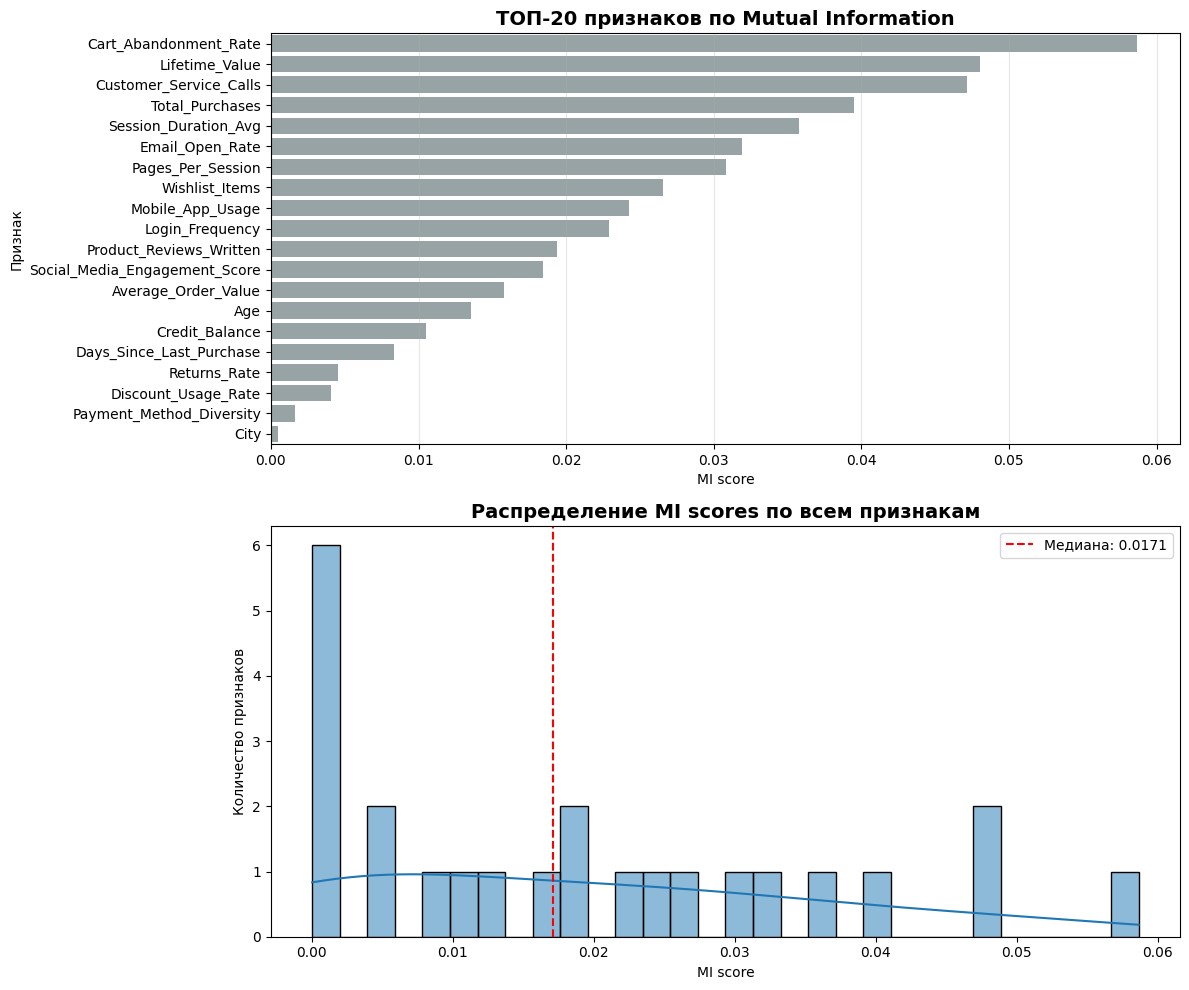

СВОДНАЯ СТАТИСТИКА:
Средний MI score: 0.0193
Медианный MI score: 0.0171
Максимальный MI score: 0.0587 (Cart_Abandonment_Rate)
Минимальный MI score: 0.0000 (Gender)

Статистически значимых признаков (p < 0.05): 0

ВЫВОД:
--------------------------------------------------------------------------------
Наиболее информативные признаки для прогноза оттока:
  1. Cart_Abandonment_Rate: 0.0587
  2. Lifetime_Value: 0.0481
  3. Customer_Service_Calls: 0.0472
  4. Total_Purchases: 0.0395
  5. Session_Duration_Avg: 0.0358


In [ ]:
# @title Инструмент 6. Mutual Information

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import RobustScaler

# Если alpha не определен выше, зададим стандартно
try:
    alpha
except NameError:
    alpha = 0.05

# =========================================================
# НАСТРОЙКИ
# =========================================================

# Поставь True, если реально нужна permutation-проверка значимости.
# Но для лабораторной по KNN/SVM/RF это обычно не обязательно.
RUN_PERMUTATION_TEST = False

# Сколько перестановок делать, если RUN_PERMUTATION_TEST = True
N_PERMUTATIONS = 100

# Для скольких верхних признаков считать p-value
TOP_N_PERMUTATION = 10

# Количество соседей для оценки MI
MI_N_NEIGHBORS = 5


print("=" * 80)
print("MUTUAL INFORMATION — оценка силы связи признаков с оттоком")
print("=" * 80)
print()

# =========================================================
# 1. Сборка признаков
# =========================================================

# feat_cols — числовые признаки
# cat_cols — категориальные признаки, уже закодированные через factorize
feature_cols = feat_cols + list(cat_cols)

X = df[feature_cols].copy()
y = df['Churned'].astype(int)

# Защита, если строк стало мало после удаления выбросов
MI_N_NEIGHBORS = min(MI_N_NEIGHBORS, max(1, len(y) - 1))

print(f"Строк в данных: {len(X)}")
print(f"Признаков: {X.shape[1]}")
print(f"Числовых признаков: {len(feat_cols)}")
print(f"Категориальных признаков: {len(cat_cols)}")
print(f"n_neighbors для MI: {MI_N_NEIGHBORS}")
print()

# =========================================================
# 2. Масштабируем только числовые признаки
# =========================================================
# Категориальные признаки после factorize — это коды категорий.
# Их масштабировать нельзя, иначе нарушится смысл дискретных значений.

X_mi = X.copy()

if len(feat_cols) > 0:
    scaler = RobustScaler()
    X_mi[feat_cols] = scaler.fit_transform(X_mi[feat_cols])

# =========================================================
# 3. Маска дискретных признаков
# =========================================================

cat_cols_set = set(cat_cols)

discrete_mask = np.array(
    [col in cat_cols_set for col in X_mi.columns],
    dtype=bool
)

# =========================================================
# 4. Расчет Mutual Information
# =========================================================

mi_scores = mutual_info_classif(
    X_mi,
    y,
    discrete_features=discrete_mask,
    n_neighbors=MI_N_NEIGHBORS,
    random_state=42
)

mi_table = pd.DataFrame({
    'Признак': X_mi.columns,
    'MI_score': mi_scores,
    'Тип': [
        'категориальный' if col in cat_cols_set else 'числовой'
        for col in X_mi.columns
    ]
}).sort_values('MI_score', ascending=False).reset_index(drop=True)

mi_table['Ранг'] = range(1, len(mi_table) + 1)

# Нормировка MI к [0, 1]
max_mi = mi_table['MI_score'].max()
if max_mi > 0:
    mi_table['MI_norm'] = mi_table['MI_score'] / max_mi
else:
    mi_table['MI_norm'] = 0.0

# =========================================================
# 5. Вывод топ-15
# =========================================================

print("ТОП-15 признаков по Mutual Information:")
print("-" * 80)

for idx, row in mi_table.head(15).iterrows():
    bar = "█" * int(row['MI_norm'] * 40)
    print(
        f"{row['Ранг']:2}. "
        f"{row['Признак']:<35} "
        f"MI={row['MI_score']:.4f} "
        f"{bar}"
    )

print()

# =========================================================
# 6. Permutation test — опционально
# =========================================================

if RUN_PERMUTATION_TEST:

    print("Расчет статистической значимости через permutation test...")
    print(f"Проверяем топ-{TOP_N_PERMUTATION} признаков, перестановок: {N_PERMUTATIONS}")
    print("Это может занять время.")
    print()

    def permutation_mi_test(
        X,
        y,
        feature_idx,
        discrete_mask,
        n_permutations=100,
        random_state=42,
        n_neighbors=5
    ):
        """
        Проверка значимости MI для одного признака.

        Важно:
        Мы берем только одну колонку X.iloc[:, [feature_idx]],
        поэтому discrete_features должен быть длиной 1:
        [True], если признак категориальный,
        [False], если признак числовой.
        """

        rng = np.random.default_rng(random_state)

        X_one = X.iloc[:, [feature_idx]]
        y_values = np.asarray(y)

        # Булев флаг именно для одной колонки
        disc_one = np.array(
            [bool(discrete_mask[feature_idx])],
            dtype=bool
        )

        # Защита от слишком большого n_neighbors
        n_neighbors = min(n_neighbors, max(1, len(y_values) - 1))

        # Исходный MI
        mi_original = mutual_info_classif(
            X_one,
            y_values,
            discrete_features=disc_one,
            n_neighbors=n_neighbors,
            random_state=random_state
        )[0]

        # Нулевое распределение MI при перемешанной цели
        mi_null = np.empty(n_permutations)

        for i in range(n_permutations):
            y_perm = rng.permutation(y_values)

            mi_null[i] = mutual_info_classif(
                X_one,
                y_perm,
                discrete_features=disc_one,
                n_neighbors=n_neighbors,
                random_state=random_state
            )[0]

        # p-value с поправкой, чтобы не получать ровно 0
        p_value = (1 + np.sum(mi_null >= mi_original)) / (n_permutations + 1)

        return mi_original, p_value

    top_features_idx = mi_table.head(TOP_N_PERMUTATION).index.tolist()
    p_values = []

    for idx in top_features_idx:
        feature_name = mi_table.loc[idx, 'Признак']
        feature_col_idx = list(X_mi.columns).index(feature_name)

        _, p_val = permutation_mi_test(
            X_mi,
            y,
            feature_col_idx,
            discrete_mask,
            n_permutations=N_PERMUTATIONS,
            random_state=42,
            n_neighbors=MI_N_NEIGHBORS
        )

        p_values.append(p_val)

    mi_table['p-value'] = np.nan
    mi_table.loc[top_features_idx, 'p-value'] = p_values

    mi_table['Значимость'] = mi_table['p-value'].apply(
        lambda x: (
            'значим'
            if pd.notna(x) and x < alpha
            else 'не значим'
            if pd.notna(x)
            else 'не тестировался'
        )
    )

else:

    mi_table['p-value'] = np.nan
    mi_table['Значимость'] = 'не тестировался'

    print("Permutation test выключен.")
    print("Для лабораторной по классификации это нормально: MI рейтинг уже получен.")
    print("Если хочешь p-value, поставь RUN_PERMUTATION_TEST = True.")
    print()

# =========================================================
# 7. Таблица результатов
# =========================================================

print("Таблица Mutual Information:")
print("-" * 100)

display_cols = [
    'Ранг',
    'Признак',
    'Тип',
    'MI_score',
    'MI_norm',
    'p-value',
    'Значимость'
]

mi_table_display = mi_table[display_cols].copy()
mi_table_display['MI_score'] = mi_table_display['MI_score'].round(4)
mi_table_display['MI_norm'] = mi_table_display['MI_norm'].round(4)
mi_table_display['p-value'] = mi_table_display['p-value'].apply(
    lambda x: f"{x:.4f}" if pd.notna(x) else "-"
)

print(mi_table_display.to_string(index=False))
print()

# =========================================================
# 8. Визуализация
# =========================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# График 1: Top-20 признаков
top_20 = mi_table.head(20)

colors = [
    '#2ecc71' if x == 'значим' else '#95a5a6'
    for x in top_20['Значимость']
]

sns.barplot(
    data=top_20,
    x='MI_score',
    y='Признак',
    order=top_20['Признак'],
    ax=axes[0],
    palette=colors
)

axes[0].set_title(
    'ТОП-20 признаков по Mutual Information',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('MI score')
axes[0].set_ylabel('Признак')
axes[0].grid(axis='x', alpha=0.3)

# График 2: Распределение MI scores
sns.histplot(
    data=mi_table,
    x='MI_score',
    bins=30,
    ax=axes[1],
    kde=True
)

median_mi = mi_table['MI_score'].median()

axes[1].set_title(
    'Распределение MI scores по всем признакам',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('MI score')
axes[1].set_ylabel('Количество признаков')
axes[1].axvline(
    median_mi,
    color='red',
    linestyle='--',
    label=f'Медиана: {median_mi:.4f}'
)
axes[1].legend()

plt.tight_layout()
plt.show()

# =========================================================
# 9. Сводная статистика
# =========================================================

print("=" * 80)
print("СВОДНАЯ СТАТИСТИКА:")
print("=" * 80)

print(f"Средний MI score: {mi_table['MI_score'].mean():.4f}")
print(f"Медианный MI score: {median_mi:.4f}")
print(
    f"Максимальный MI score: "
    f"{mi_table['MI_score'].max():.4f} "
    f"({mi_table.iloc[0]['Признак']})"
)
print(
    f"Минимальный MI score: "
    f"{mi_table['MI_score'].min():.4f} "
    f"({mi_table.iloc[-1]['Признак']})"
)
print()

significant = mi_table[mi_table['Значимость'] == 'значим']

print(f"Статистически значимых признаков (p < {alpha}): {len(significant)}")

if len(significant) > 0:
    print("Значимые признаки:")
    for _, row in significant.iterrows():
        print(
            f"  - {row['Признак']} "
            f"(MI={row['MI_score']:.4f}, p={row['p-value']:.4f})"
        )

print()
print("ВЫВОД:")
print("-" * 80)

top_5 = mi_table.head(5)['Признак'].tolist()

print("Наиболее информативные признаки для прогноза оттока:")

for i, feat in enumerate(top_5, 1):
    mi_val = mi_table.loc[mi_table['Признак'] == feat, 'MI_score'].values[0]
    print(f"  {i}. {feat}: {mi_val:.4f}")

# Лабораторная работа №2. Классификация клиентов по оттоку

Цель — предсказать класс `Churned`: 0 — клиент остался, 1 — клиент ушёл.
Прогноз может использоваться для выбора клиентов для мер удержания. Precision
показывает долю действительно ушедших среди предсказанных, Recall — долю
обнаруженных ушедших клиентов. F1 учитывает оба показателя.

Используются все подготовленные данные из лабораторной №1. Отдельного
разделения 70/30 в этой версии нет. GridSearchCV проводит трёхкратную
стратифицированную кросс-валидацию, затем автоматически обучает лучшую модель
на всём наборе (`refit=True`). Последующее повторное обучение не требуется.

Масштабирование включено в Pipeline: на каждом шаге проверки скейлер обучается
только на обучающих строках. Подготовка из лабораторной №1 сохранена;
заполнение пропусков и обработка выбросов там выполнялись до кросс-валидации.
Поэтому результаты относятся к уже подготовленному набору.


In [ ]:
# @title 1. Все подготовленные данные и схема проверки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

X = df.drop(columns='Churned').copy()
y = df['Churned'].copy()
assert set(y.unique()) == {0, 1}, 'Ожидаются классы Churned 0 и 1'
assert X.select_dtypes(exclude=['number', 'bool']).empty, 'Выполните кодирование из лабораторной №1'
assert not X.isna().any().any(), 'Выполните заполнение пропусков из лабораторной №1'
assert np.isfinite(X.to_numpy(dtype=float)).all(), 'В признаках есть бесконечные значения'

numeric_features = [col for col in X.columns if col not in cat_cols]
preprocessor = ColumnTransformer(
    [('numeric', RobustScaler(), numeric_features)],
    remainder='passthrough'
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {'Accuracy': 'accuracy', 'Precision': 'precision',
           'Recall': 'recall', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
# Два параллельных процесса ограничивают потребление памяти в Colab.
N_JOBS = 2
searches = {}
print(f'Объектов: {len(X)}, признаков: {X.shape[1]}')
print('Количество объектов по классам:')
display(y.value_counts().sort_index().rename('Количество'))


def fit_search(name, estimator, param_grid, scale=True):
    pipeline = Pipeline([
        ('preprocessing', clone(preprocessor) if scale else 'passthrough'),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipeline, param_grid, scoring=scoring, refit='F1', cv=cv,
        n_jobs=N_JOBS, pre_dispatch=N_JOBS, verbose=1, error_score='raise'
    )
    search.fit(X, y)
    searches[name] = search
    print(f'{name}: лучшие параметры — {search.best_params_}')
    print(f'Средняя F1 на CV: {search.best_score_:.4f}')
    print(f'Лучшая модель обучена на всех {len(X)} строках.')
    return search


In [ ]:
# @title 2. KNN: подбор параметров и обучение на всех данных
# 6 комбинаций × 3 части = 18 обучений и итоговое обучение.
# Евклидово расстояние; повторяющий его Minkowski с p=2 не перебираем.
grid_search = fit_search(
    'KNN', KNeighborsClassifier(n_jobs=1),
    {'model__n_neighbors': [5, 13, 21],
     'model__weights': ['uniform', 'distance']}
)
best_knn = grid_search.best_estimator_


In [ ]:
# @title 3. График выбора числа соседей без повторного обучения
cv_knn = pd.DataFrame(grid_search.cv_results_)
plt.figure(figsize=(9, 5))
for weights in ['uniform', 'distance']:
    part = cv_knn[cv_knn['param_model__weights'] == weights].sort_values(
        'param_model__n_neighbors'
    )
    plt.plot(part['param_model__n_neighbors'].astype(int),
             part['mean_test_F1'], marker='o', label=weights)
plt.xlabel('Число соседей K')
plt.ylabel('Средняя F1 на кросс-валидации')
plt.title('Подбор K для KNN')
plt.legend(title='Веса соседей')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# @title 4. SVM: подбор параметров и обучение на всех данных
# LinearSVC — линейный метод опорных векторов для большого числа строк.
# Для ROC используются decision_function, расчёт вероятностей не требуется.
grid_search_svm = fit_search(
    'SVM', LinearSVC(dual=False, max_iter=20000, random_state=42),
    {'model__C': [0.1, 1.0]}
)
best_svm = grid_search_svm.best_estimator_


In [ ]:
# @title 5. Random Forest: подбор параметров и обучение на всех данных
# Для деревьев масштабирование не требуется.
grid_search_rf = fit_search(
    'Random Forest', RandomForestClassifier(random_state=42, n_jobs=1),
    {'model__n_estimators': [100],
     'model__max_depth': [None, 10],
     'model__min_samples_leaf': [1, 5]},
    scale=False
)
best_rf = grid_search_rf.best_estimator_


## Оценка выбранных моделей

В общей таблице ниже приведены средние метрики кросс-валидации для выбранных
параметров. Для матриц ошибок и ROC каждая строка получает прогноз модели,
которая не обучалась на этой строке (out-of-fold). Для экономии вычислений
класс определяется из того же прогноза: порог 0,5 для вероятностей и 0 для
оценки SVM. При вероятности ровно 0,5 выбирается класс 0.

**Ограничение:** параметры выбраны по тем же разбиениям. Поэтому оценки могут
быть оптимистичными и не являются независимой тестовой оценкой. Для такой
оценки нужны отдельная тестовая выборка или вложенная кросс-валидация.
Итоговые модели, обученные на всех строках, сохраняются; получение
out-of-fold прогнозов обучает отдельные копии.


In [ ]:
# @title 6. Сравнительная таблица кросс-валидации
rows = []
for name, search in searches.items():
    index = search.best_index_
    row = {'Модель': name}
    for metric in scoring:
        row[metric] = search.cv_results_[f'mean_test_{metric}'][index]
    row['F1 std'] = search.cv_results_['std_test_F1'][index]
    rows.append(row)
results_df = pd.DataFrame(rows).set_index('Модель').sort_values('F1', ascending=False)
display(results_df.round(4))
print('Средние метрики CV; не метрики на отдельной тестовой выборке.')


In [ ]:
# @title 7. Прогнозы для матриц ошибок и ROC
# Дополнительно 3 обучения на модель. Полный Grid Search не повторяется.
oof_predictions = {}
oof_scores = {}
for name, search in searches.items():
    is_svm = name == 'SVM'
    print(f'Получение прогнозов вне обучающих частей: {name}...')
    values = cross_val_predict(
        search.best_estimator_, X, y, cv=cv,
        method='decision_function' if is_svm else 'predict_proba',
        n_jobs=N_JOBS, pre_dispatch=N_JOBS
    )
    scores = values if is_svm else values[:, 1]
    oof_scores[name] = scores
    oof_predictions[name] = (scores > (0.0 if is_svm else 0.5)).astype(int)
    print(classification_report(y, oof_predictions[name],
                                target_names=['Остался (0)', 'Ушёл (1)'],
                                zero_division=0))


In [ ]:
# @title 8. Матрицы ошибок
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, prediction) in zip(axes, oof_predictions.items()):
    sns.heatmap(confusion_matrix(y, prediction, labels=[0, 1]),
                annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
    ax.set_title(f'{name}: прогнозы вне обучения')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()


In [ ]:
# @title 9. ROC-кривые
plt.figure(figsize=(9, 6))
for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y, scores)
    plt.plot(fpr, tpr, label=f'{name}: AUC = {roc_auc_score(y, scores):.4f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Доля ложных срабатываний (FPR)')
plt.ylabel('Доля обнаруженных ушедших (TPR)')
plt.title('ROC по прогнозам вне обучающих частей')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# @title 10. Важность признаков случайного леса
feature_imp_df = pd.DataFrame({
    'Признак': X.columns,
    'Важность': best_rf.named_steps['model'].feature_importances_
}).sort_values('Важность', ascending=False)
plt.figure(figsize=(10, 7))
sns.barplot(data=feature_imp_df.head(20), x='Важность', y='Признак', color='steelblue')
plt.title('Важность признаков случайного леса, обученного на всех данных')
plt.tight_layout()
plt.show()
display(feature_imp_df.head(5))


In [ ]:
# @title 11. Итоговый вывод по полученным результатам
leader = results_df.index[0]
row = results_df.loc[leader]
final_knn = best_knn
final_svm = best_svm
final_rf = best_rf
print('Обучены KNN, линейная SVM и случайный лес.')
print('Параметры подобраны GridSearchCV по F1 на трёхкратной кросс-валидации.')
print(f'Наибольшая средняя F1 получена у {leader}: {row["F1"]:.4f}.')
print(f'Средняя Precision: {row["Precision"]:.4f}; средняя Recall: {row["Recall"]:.4f}.')
print('Оценки получены при подборе параметров и не заменяют независимый тест.')
print(f'Все три итоговые модели обучены на {len(X)} строках и {X.shape[1]} признаках.')
print('Модели вместе с необходимым масштабированием: final_knn, final_svm, final_rf.')
print('Прогнозы могут использоваться для выбора мер удержания клиентов;')
print('экономический эффект требует данных о стоимости и результативности этих мер.')
